In [31]:
import numpy as np
import pandas as pd

# 1. Caricamento del dataset
df = pd.read_csv("../data/processed/dataset.csv")

# 2. Alias automatici per evitare KeyError sui nomi delle feature
if "subreddits_obs_conspiracy_score" in df.columns:
    df["subreddit_obs_conspiracy_score"] = df["subreddits_obs_conspiracy_score"]
if "growing_exclusivity_contributions" in df.columns:
    df["growing_exclusibity_contributions"] = df[
        "growing_exclusivity_contributions"
    ]

# 3. Creazione sicura della colonna di raggruppamento (gestisce bool, stringhe 'True'/'False', 1/0)
is_anchor_clean = (
    df["is_anchor"].astype(str).str.strip().str.lower().isin(["true", "1", "t"])
)
df["group_label"] = np.where(is_anchor_clean, "Anchor", "Non-Anchor")

print("Dataset pronto!")
print(df["group_label"].value_counts())

Dataset pronto!
group_label
Anchor        98
Non-Anchor    98
Name: count, dtype: int64


In [32]:
from matplotlib.ticker import ScalarFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
import seaborn as sns

PALETTE = {
    "Non-Anchor": "#2b5c8f",
    "Anchor": "#d95f02",
}


def plot_feature_grid(
    df,
    features,
    title_group,
    n_cols=2,
    custom_xlims=None,
    log_features=None,
    robust_xlim=True,
    bw_adjust=0.85,
    show_stats=True,
    show_rug=True,
):
    if custom_xlims is None:
        custom_xlims = {}
    if log_features is None:
        log_features = []

    plot_df = df.copy()

    # Creazione sicura della label di raggruppamento
    if "group_label" not in plot_df.columns:
        is_anchor_clean = (
            plot_df["is_anchor"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "t"])
        )
        plot_df["group_label"] = np.where(
            is_anchor_clean, "Anchor", "Non-Anchor"
        )

    valid_features = [f for f in features if f in plot_df.columns]
    if not valid_features:
        print("Nessuna delle feature specificate è presente nel DataFrame.")
        return

    n_features = len(valid_features)
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(7.0 * n_cols, 4.4 * n_rows),
        dpi=150,
    )

    if n_features == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes).flatten()

    for i, feature in enumerate(valid_features):
        ax = axes[i]
        is_log = feature in log_features

        # Gestione trasformazione logaritmica se richiesta
        if is_log:
            temp_col = f"{feature}_log10"
            plot_df[temp_col] = np.log10(np.maximum(plot_df[feature], 0) + 1)
            plot_var = temp_col
            clip_param = (0, None)
        else:
            plot_var = feature
            min_val = plot_df[plot_var].dropna().min()
            clip_param = (0, None) if min_val >= 0 else None

        # 1. Tracciamento KDE
        sns.kdeplot(
            data=plot_df,
            x=plot_var,
            hue="group_label",
            palette=PALETTE,
            common_norm=False,
            fill=True,
            alpha=0.28,
            linewidth=2.0,
            cut=0,
            clip=clip_param,
            bw_adjust=bw_adjust,
            ax=ax,
            legend=False,
        )

        # 2. Rugplot alla base (evidenzia i singoli utenti campionati)
        if show_rug:
            sns.rugplot(
                data=plot_df,
                x=plot_var,
                hue="group_label",
                palette=PALETTE,
                height=0.06,
                alpha=0.75,
                lw=1.1,
                ax=ax,
                legend=False,
            )

        # 3. Mediane calcolate e formattate per la legenda
        medians = plot_df.groupby("group_label")[plot_var].median(
            numeric_only=True
        )
        orig_medians = plot_df.groupby("group_label")[feature].median(
            numeric_only=True
        )

        for group_name in ["Non-Anchor", "Anchor"]:
            if group_name in medians and pd.notna(medians[group_name]):
                m_plot = medians[group_name]
                m_orig = orig_medians[group_name]

                # Formattazione adattiva della mediana in base alla scala
                if is_log:
                    label_str = f"{group_name} (Med: {m_orig:.0f})"
                elif abs(m_orig) < 0.005 and m_orig != 0:
                    label_str = f"{group_name} (Med: {m_orig:.4f})"
                else:
                    label_str = f"{group_name} (Med: {m_orig:.3f})"

                ax.axvline(
                    m_plot,
                    color=PALETTE[group_name],
                    linestyle=":",
                    linewidth=1.8,
                    alpha=0.95,
                    label=label_str,
                )

        ax.legend(
            title="Gruppo (N=122)",
            frameon=True,
            facecolor="white",
            edgecolor="#ced4da",
            fontsize=9,
        )

        # 4. Calcolo formale del Test di Mann-Whitney U ed Effect Size
        clean_title = feature.replace("_", " ").title()
        if show_stats:
            s_non = plot_df[plot_df["group_label"] == "Non-Anchor"][
                feature
            ].dropna()
            s_anc = plot_df[plot_df["group_label"] == "Anchor"][
                feature
            ].dropna()
            u_stat, pval = mannwhitneyu(s_anc, s_non, alternative="two-sided")
            # Rank-biserial correlation come effect size per Mann-Whitney
            r_rb = abs(1 - (2 * u_stat) / (len(s_anc) * len(s_non)))

            if pval < 0.001:
                p_text = "p < 0.001***"
            elif pval < 0.01:
                p_text = f"p = {pval:.3f}**"
            elif pval < 0.05:
                p_text = f"p = {pval:.3f}*"
            else:
                p_text = f"p = {pval:.2f} (n.s.)"

            ax.set_title(clean_title, fontsize=12, fontweight="bold", pad=15)
            ax.text(
                0.5,
                1.02,
                f"Mann-Whitney U: {p_text}  |  Effect Size (r): {r_rb:.2f}",
                transform=ax.transAxes,
                ha="center",
                fontsize=9.5,
                color="#333333",
                style="italic",
            )
        else:
            ax.set_title(clean_title, fontsize=12, fontweight="bold", pad=8)

        # 5. Gestione Asse X (Custom, Logaritmico o Percentile Robusto)
        if feature in custom_xlims:
            ax.set_xlim(custom_xlims[feature])
        elif is_log:
            max_val_log = plot_df[plot_var].max()
            max_t = int(np.floor(max_val_log))
            ticks = list(range(0, max_t + 1))
            tick_labels = [
                "0"
                if t == 0
                else (
                    "10"
                    if t == 1
                    else ("100" if t == 2 else f"{10**(t-3)}k")
                )
                for t in ticks
            ]
            ax.set_xticks(ticks)
            ax.set_xticklabels(tick_labels)
            ax.set_xlim(0, max_val_log * 1.05)
        elif robust_xlim:
            s = plot_df[feature].dropna()
            min_v = s.min()
            max_v = s.max()
            q98 = s.quantile(0.98)
            if max_v > 1.3 * q98 and q98 > min_v:
                right_lim = q98 + (q98 - min_v) * 0.05
            else:
                right_lim = max_v + (max_v - min_v) * 0.02
            left_lim = min_v if min_v >= 0 else s.quantile(0.01)
            ax.set_xlim(left=left_lim, right=right_lim)

        if is_log:
            ax.set_xlabel("Punteggio (Scala Logaritmica)", fontsize=10)
        else:
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-2, 3))
            ax.xaxis.set_major_formatter(formatter)
            ax.set_xlabel("Valore", fontsize=10)

        ax.set_ylabel("Densità", fontsize=10)
        ax.grid(True, axis="y", alpha=0.5, linestyle="--")
        sns.despine(ax=ax, top=True, right=True)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(title_group, fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

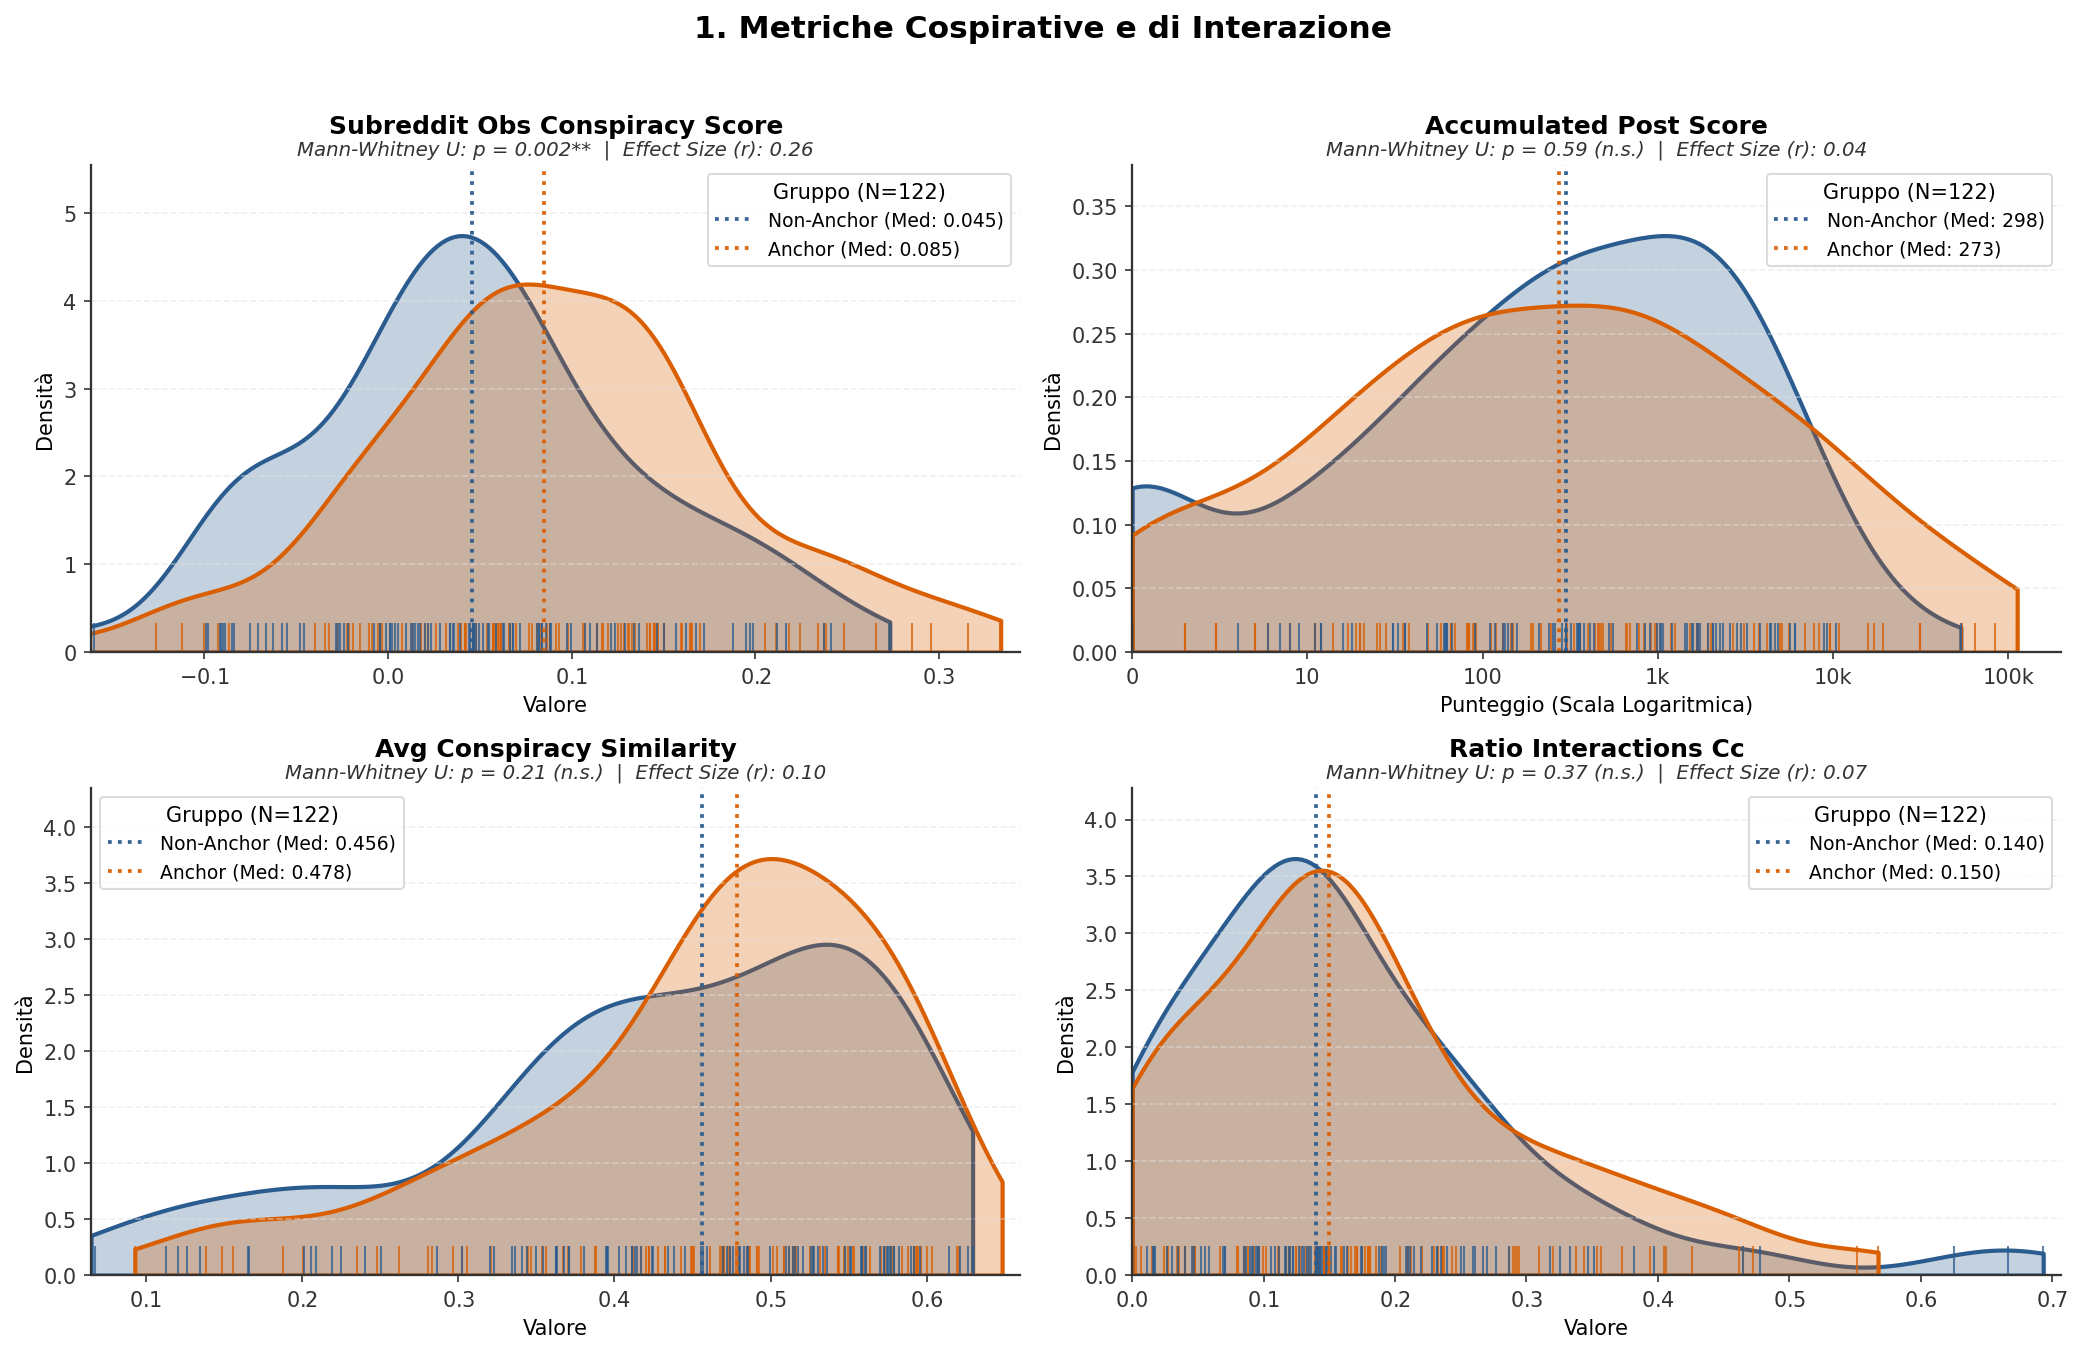

In [33]:
features_conspiracy = [
    "subreddit_obs_conspiracy_score",
    "accumulated_post_score",
    "avg_conspiracy_similarity",
    "ratio_interactions_cc",
]

# accumulated_post_score plottato in scala logaritmica con etichette chiare (0, 10, 100, 1k, 10k, 100k)
plot_feature_grid(
    df=df,
    features=features_conspiracy,
    title_group="1. Metriche Cospirative e di Interazione",
    log_features=["accumulated_post_score"],
)

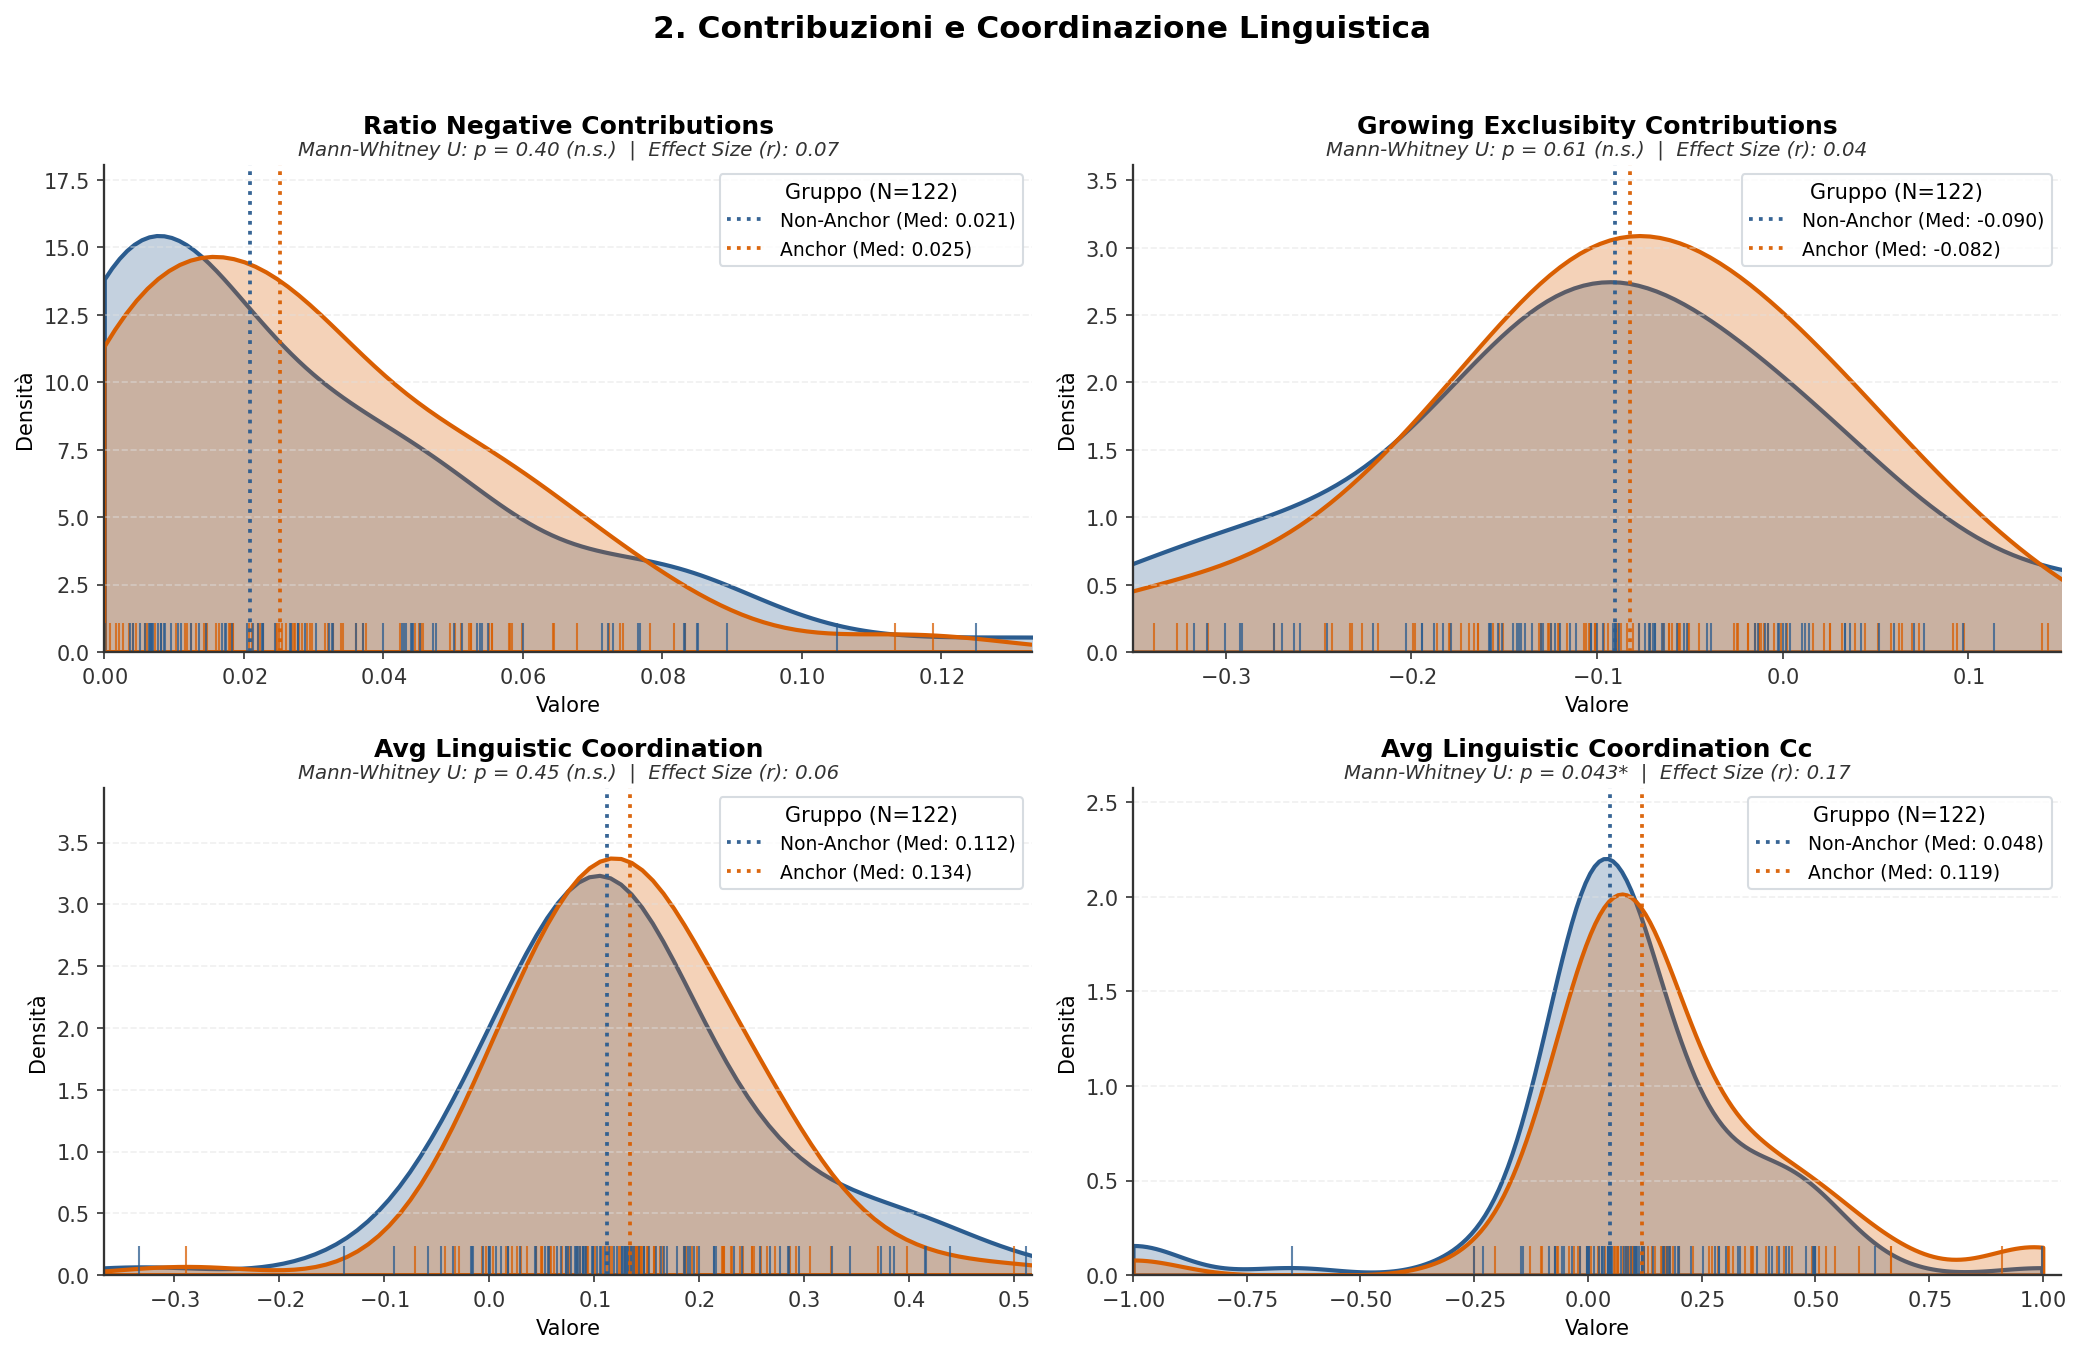

In [34]:
features_contributions = [
    "ratio_negative_contributions",
    "growing_exclusibity_contributions",
    "avg_linguistic_coordination",
    "avg_linguistic_coordination_cc",
]

# Zoom mirato sull'intervallo in cui risiede il 90% della densità per growing exclusivity
plot_feature_grid(
    df=df,
    features=features_contributions,
    title_group="2. Contribuzioni e Coordinazione Linguistica",
    custom_xlims={"growing_exclusibity_contributions": (-0.35, 0.15)},
)

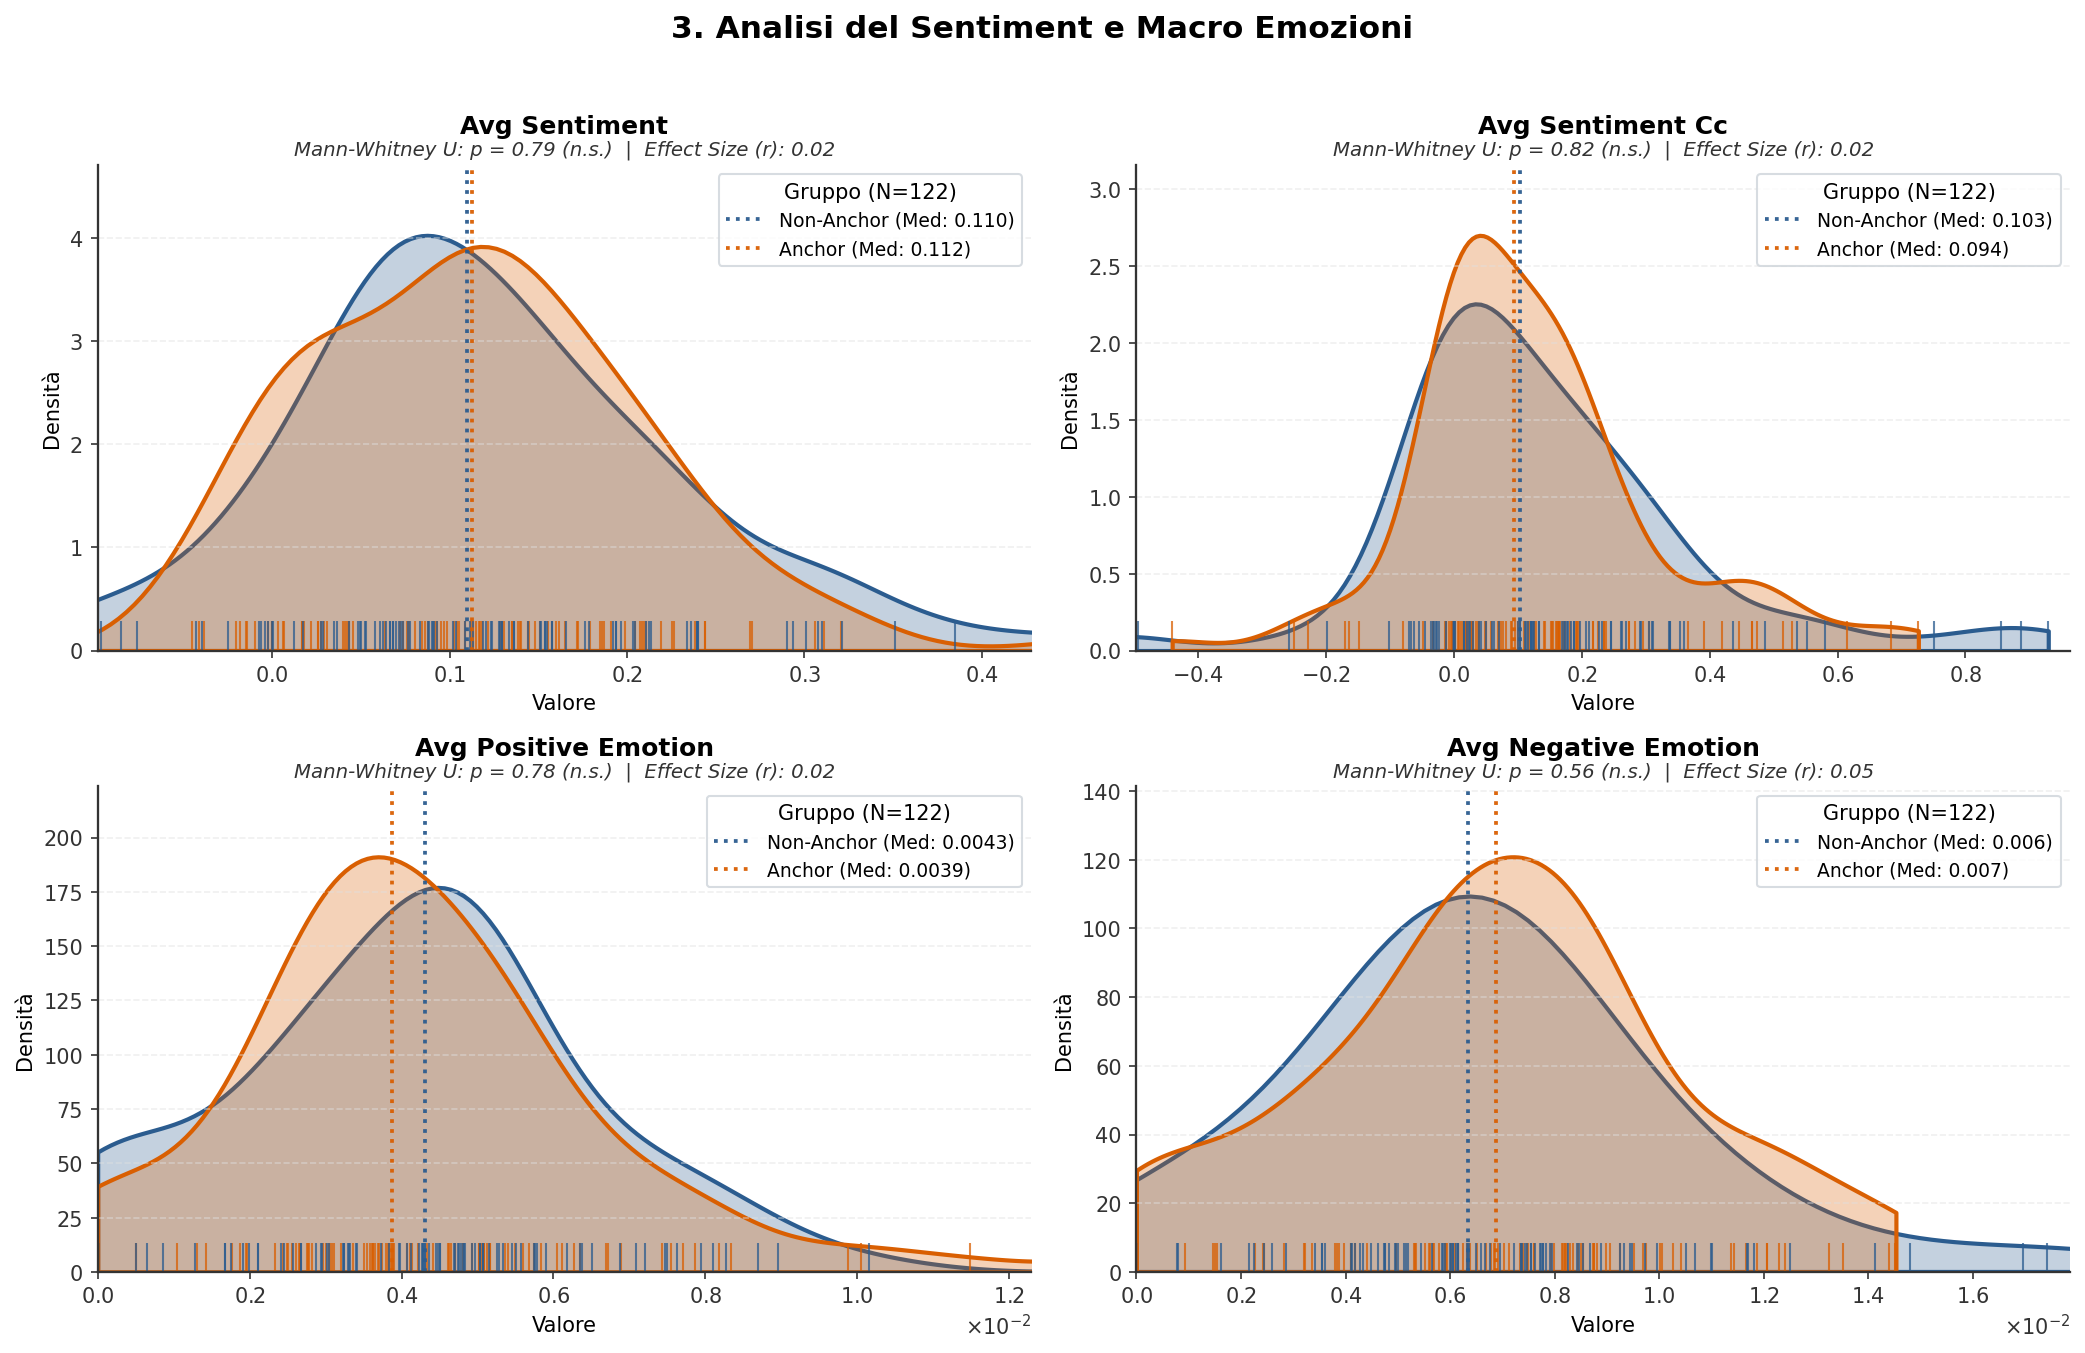

In [35]:
features_sentiment = [
    "avg_sentiment",
    "avg_sentiment_cc",
    "avg_positive_emotion",
    "avg_negative_emotion",
]

plot_feature_grid(
    df, features_sentiment, "3. Analisi del Sentiment e Macro Emozioni"
)

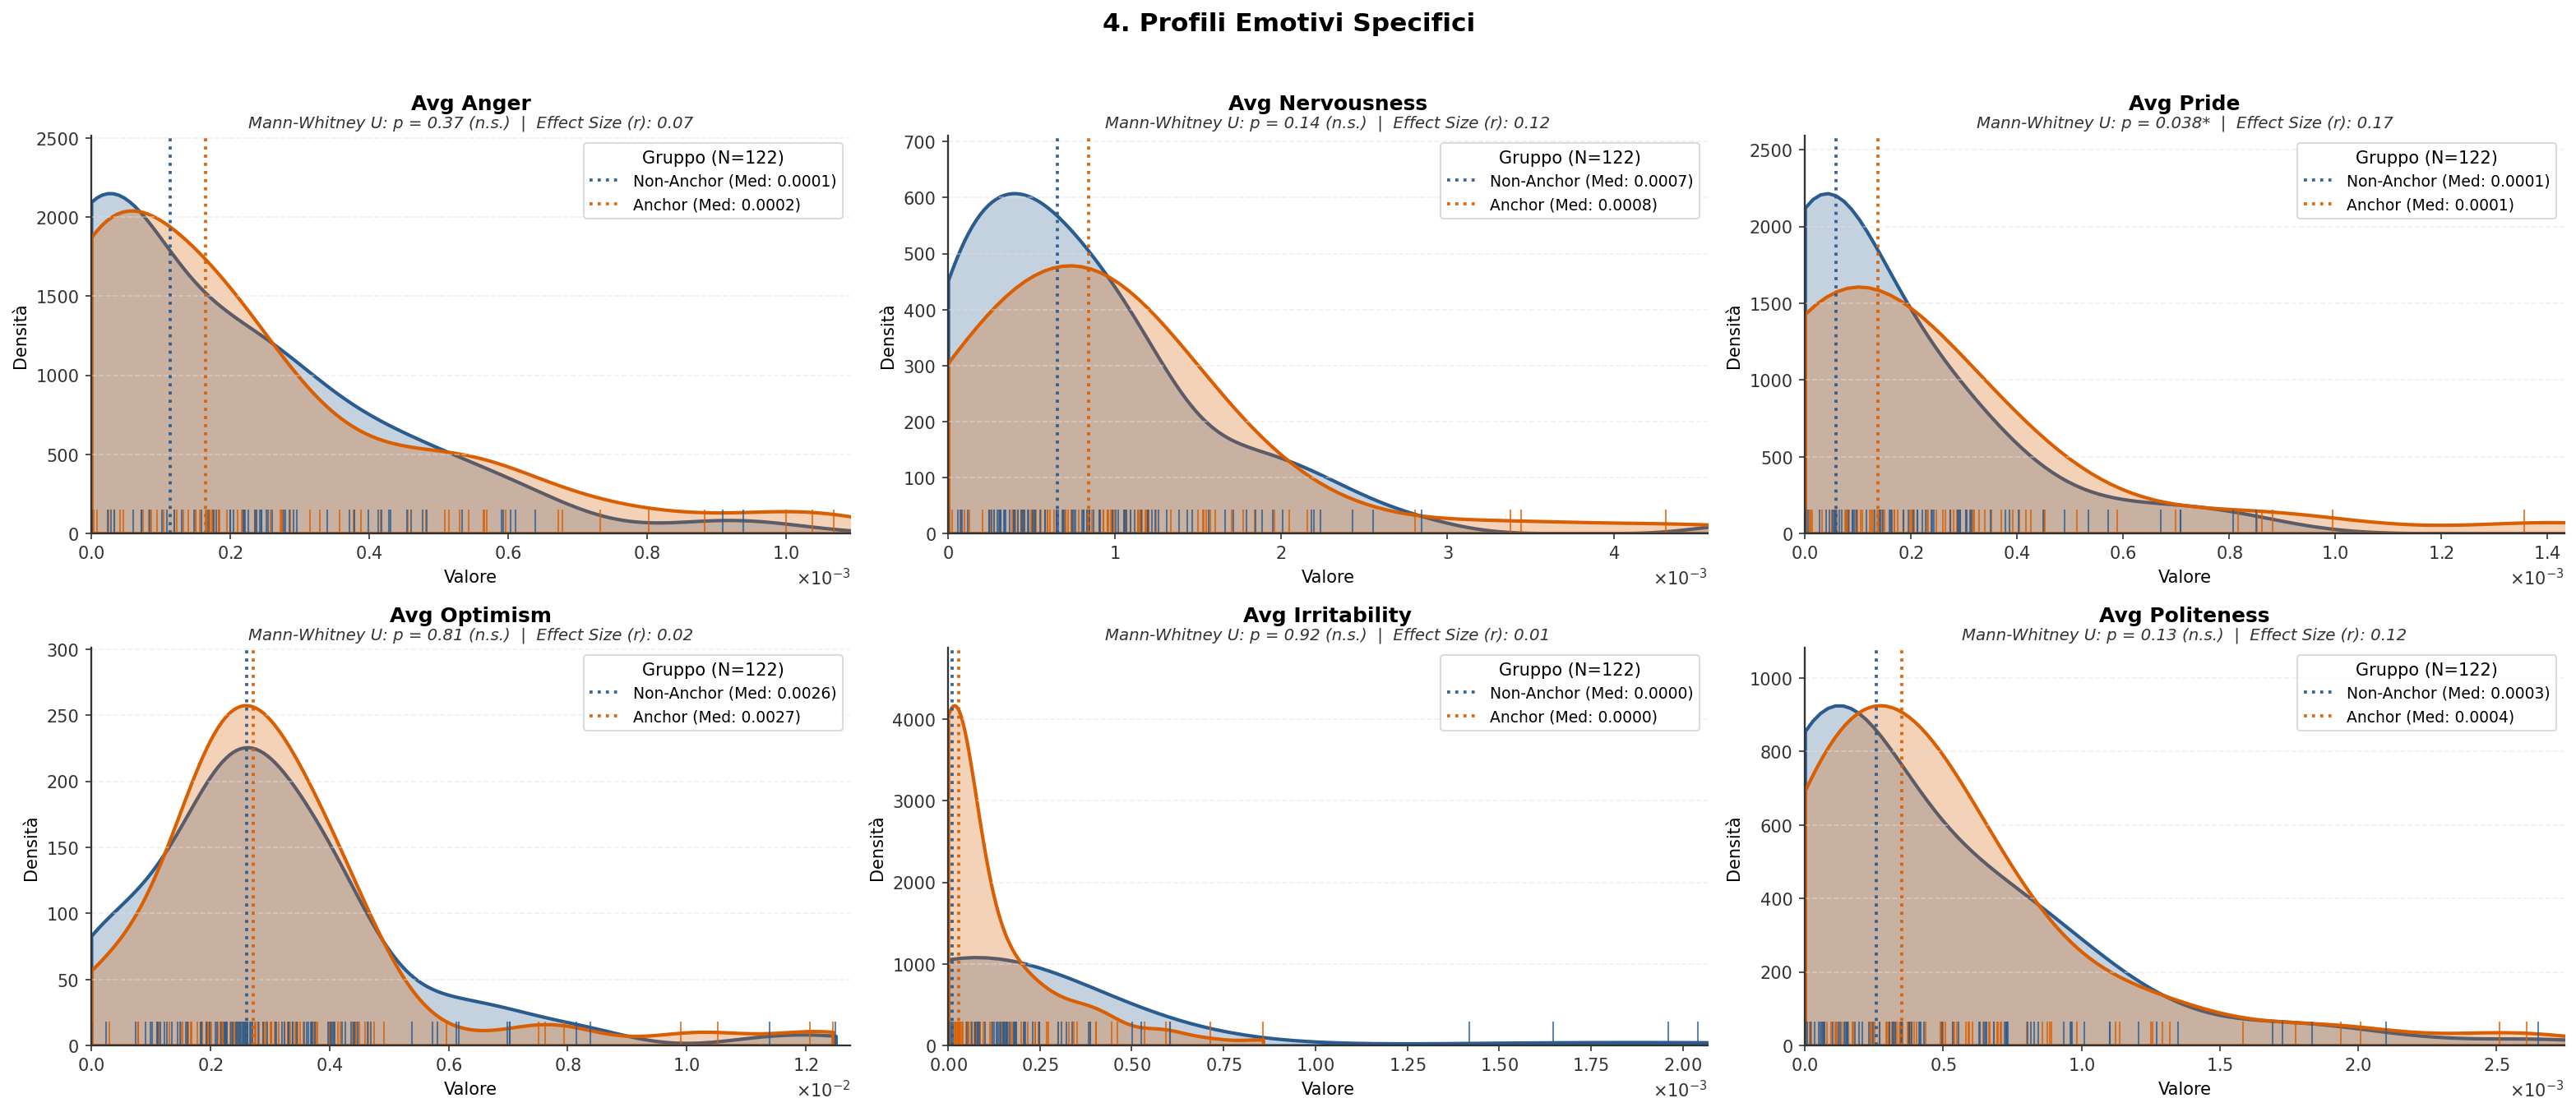

In [36]:
features_emotions = [
    "avg_anger",
    "avg_nervousness",
    "avg_pride",
    "avg_optimism",
    "avg_irritability",
    "avg_politeness",
]

plot_feature_grid(
    df, features_emotions, "4. Profili Emotivi Specifici", n_cols=3
)

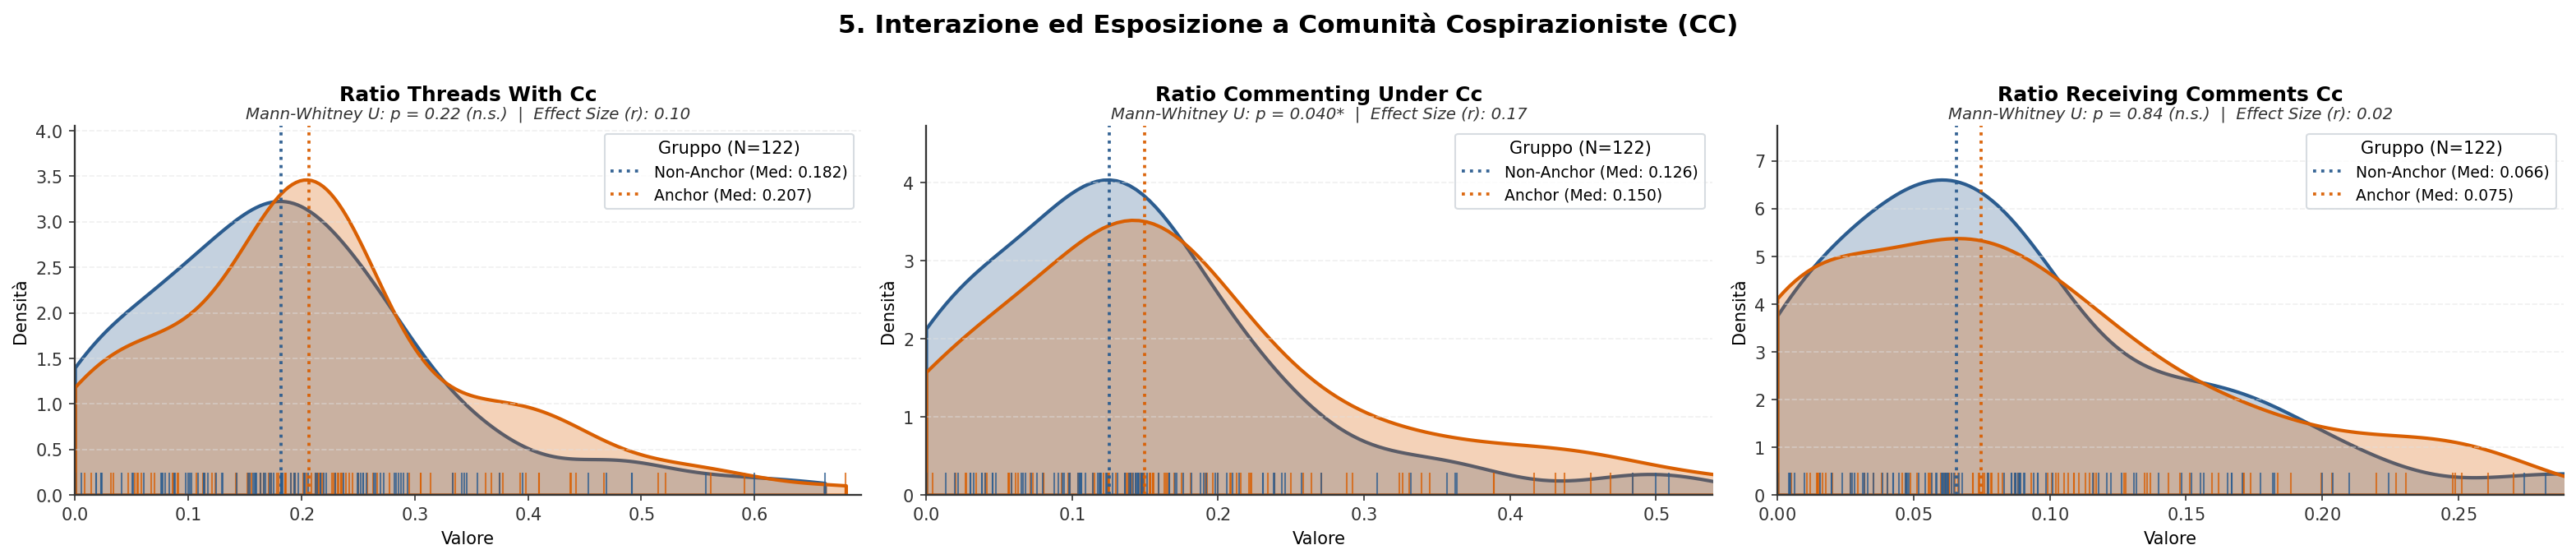

In [37]:
features_cc_interactions = [
    "ratio_threads_with_cc",
    "ratio_commenting_under_cc",
    "ratio_receiving_comments_cc",
]

plot_feature_grid(
    df=df,
    features=features_cc_interactions,
    title_group="5. Interazione ed Esposizione a Comunità Cospirazioniste (CC)",
    n_cols=3,
)

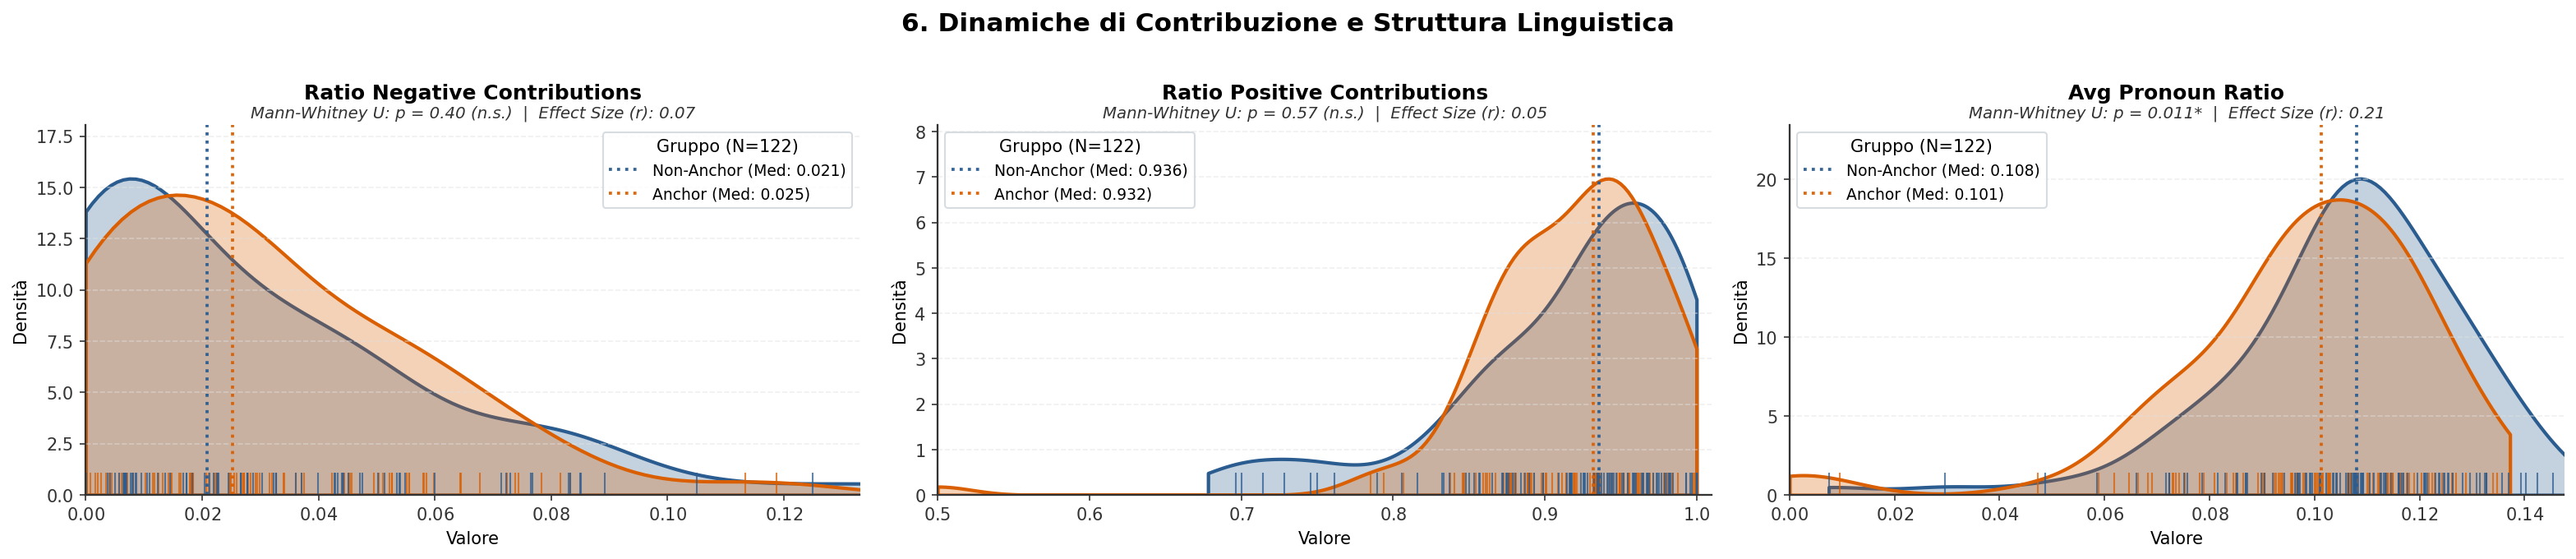

In [38]:
features_contributions_valence = [
    "ratio_negative_contributions",
    "ratio_positive_contributions",
    "avg_pronoun_ratio",
]

plot_feature_grid(
    df=df,
    features=features_contributions_valence,
    title_group="6. Dinamiche di Contribuzione e Struttura Linguistica",
    n_cols=3,
)

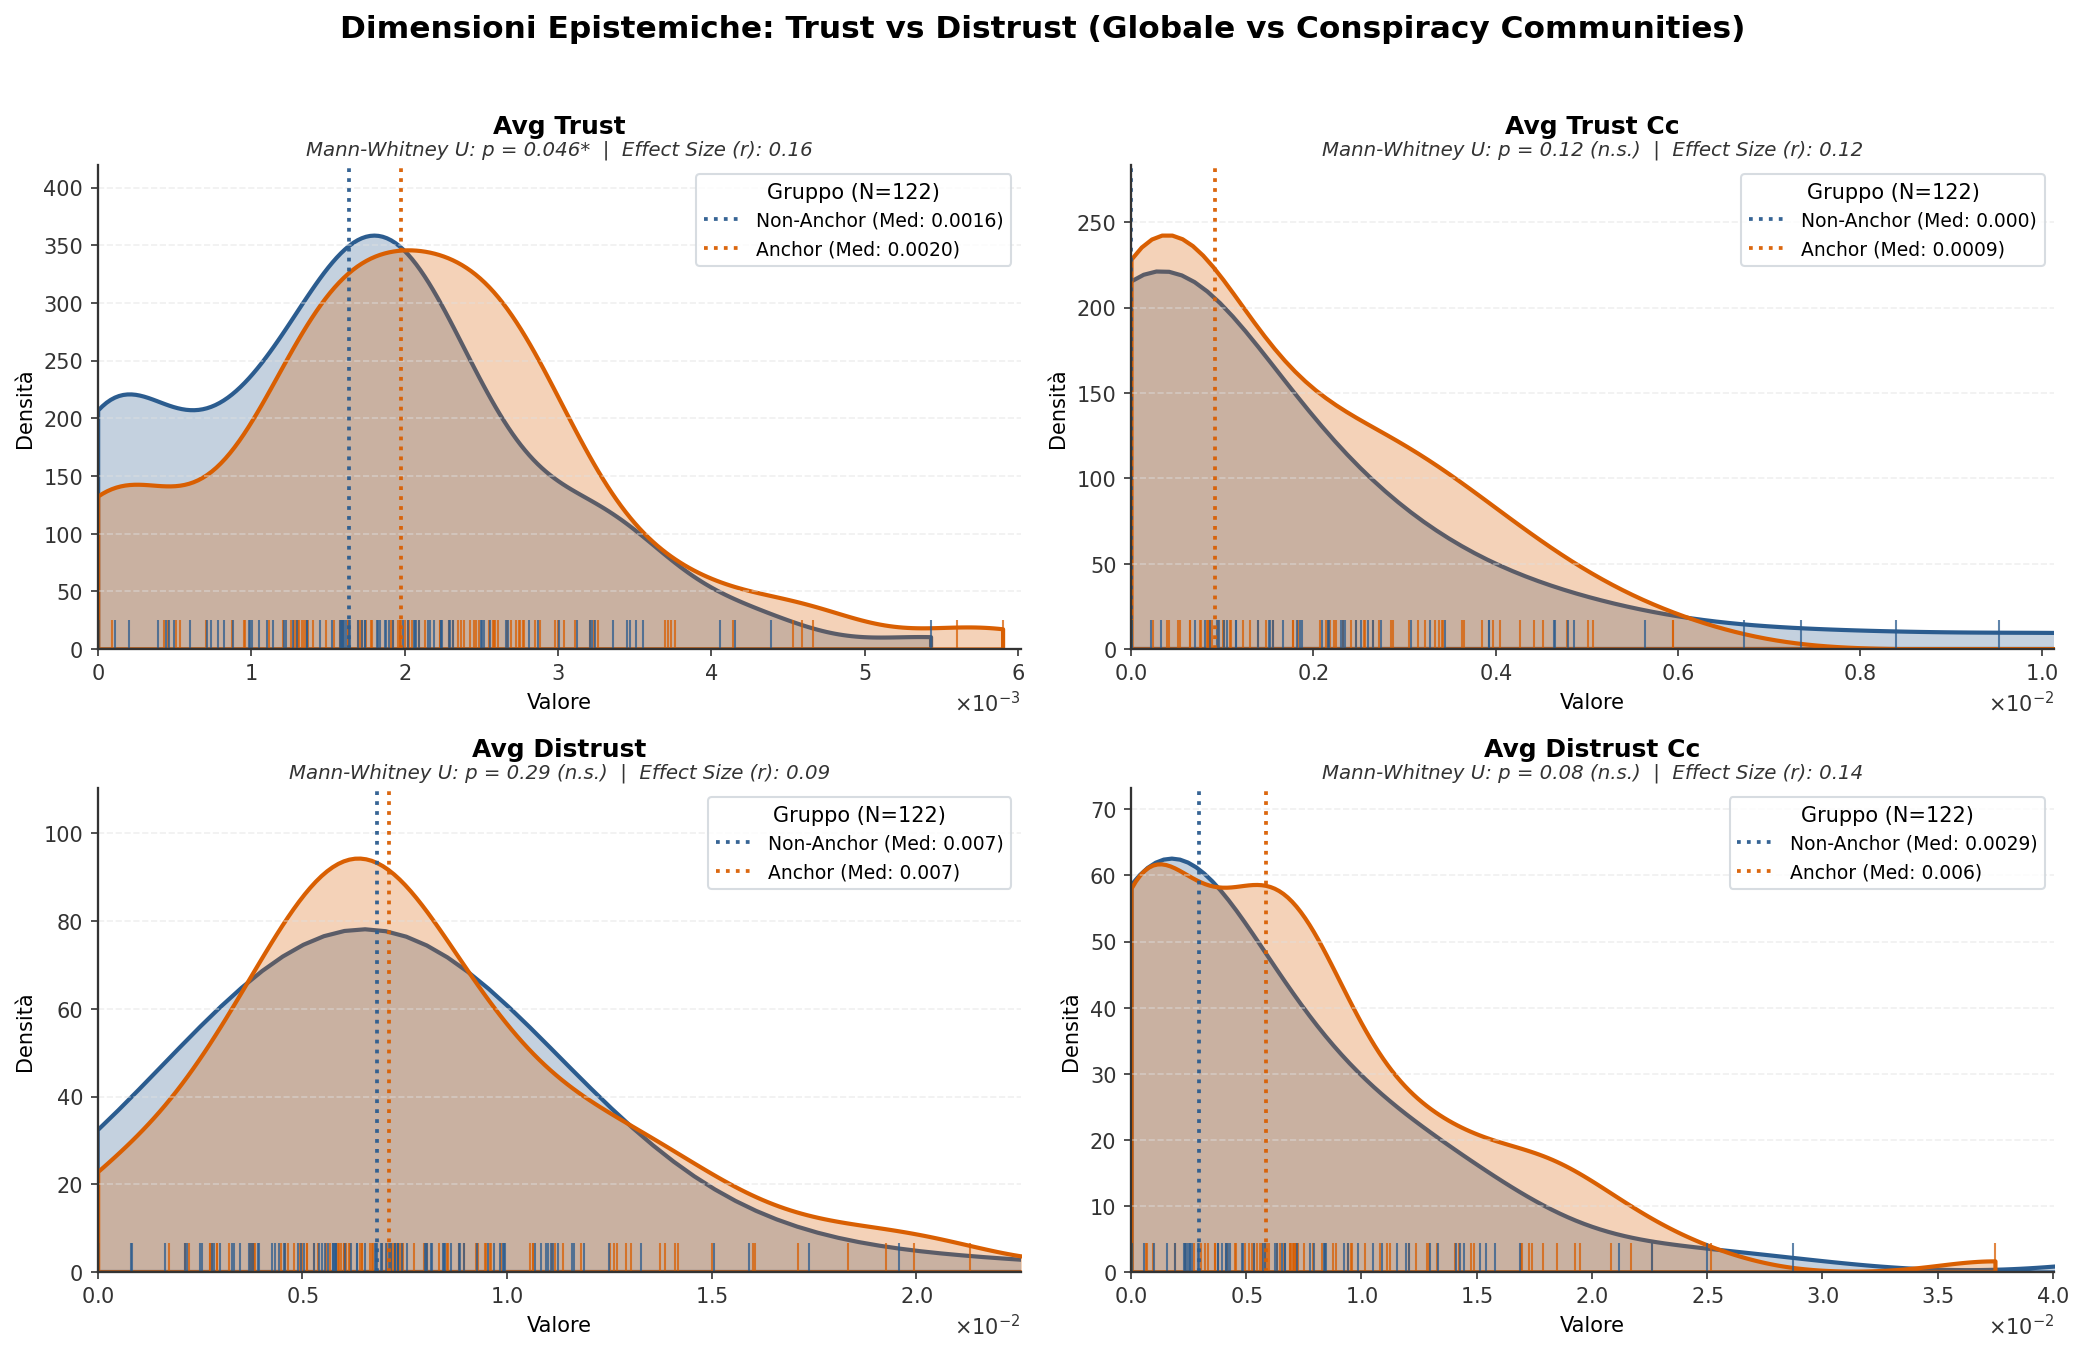

In [43]:
features_trust_distrust = [
    "avg_trust",
    "avg_trust_cc",
    "avg_distrust",
    "avg_distrust_cc",
]

plot_feature_grid(
    df=df,
    features=features_trust_distrust,
    title_group="Dimensioni Epistemiche: Trust vs Distrust (Globale vs Conspiracy Communities)",
    n_cols=2,
)

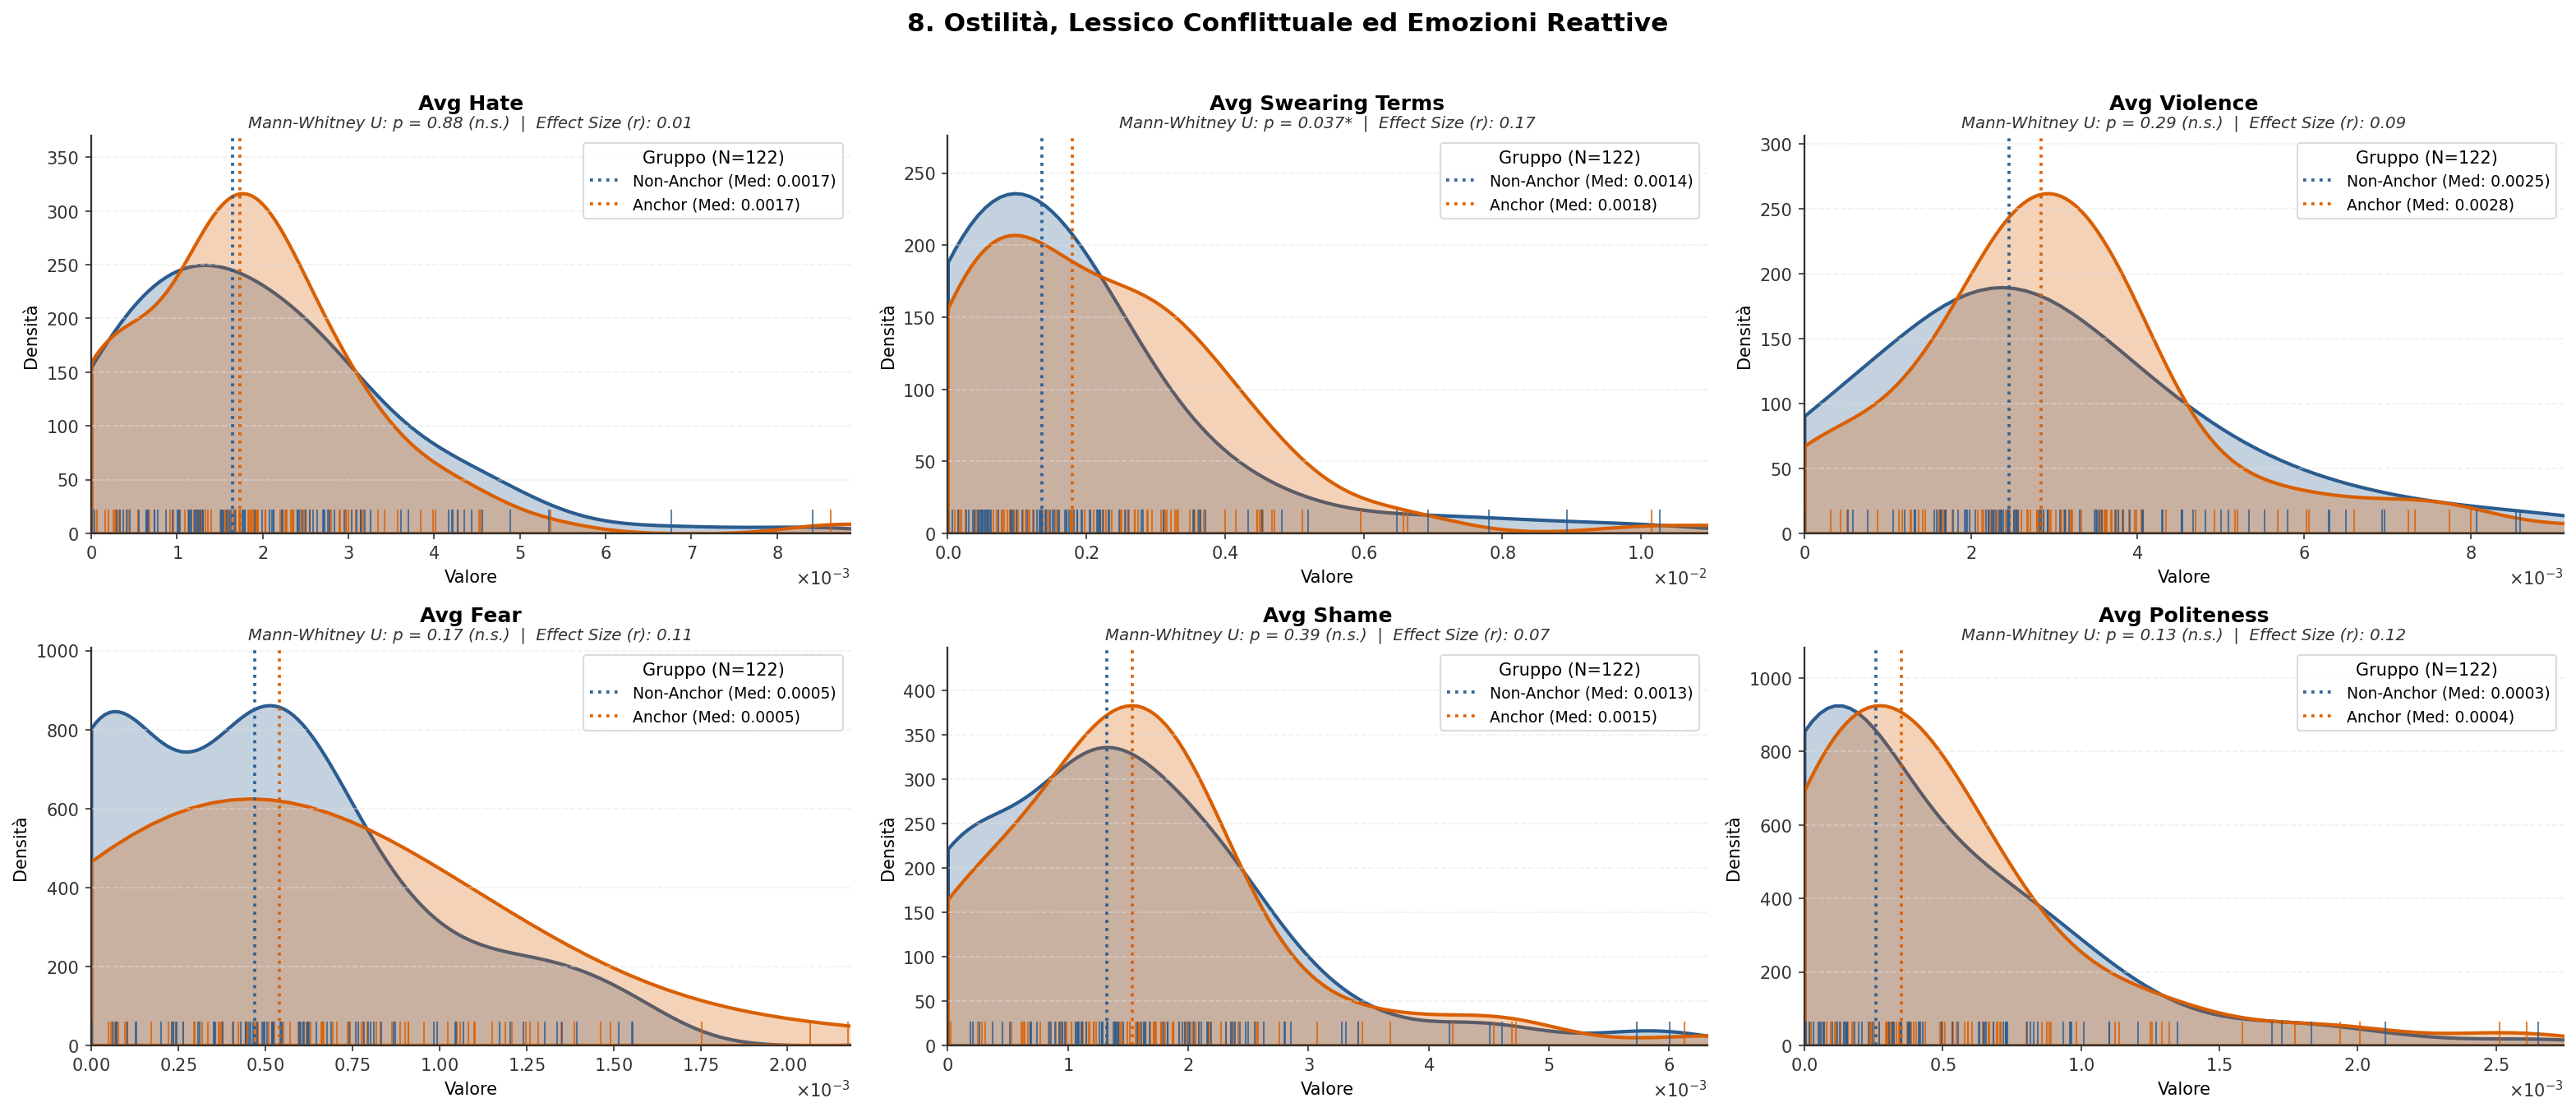

In [40]:
features_hostility_affect = [
    "avg_hate",
    "avg_swearing_terms",
    "avg_violence",
    "avg_fear",
    "avg_shame",
    "avg_politeness",
]

plot_feature_grid(
    df=df,
    features=features_hostility_affect,
    title_group="8. Ostilità, Lessico Conflittuale ed Emozioni Reattive",
    n_cols=3,
)